# Analysis for the Project: Debt-Based License Suspension

## The Main Questions:
- What are the reasons for license suspensions? [Jassim]
- What % are not falling under safety related? [Rachel, Alberto]
- What % are debt based? [Sarah]
- How many people lose their license over nothing dangerous? [Yuan, Ethan]

In [1]:
%pip install python-calamine numpy pandas pyarrow fastexcel xlsx2csv openpyxl -U --quiet

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import pathlib
import matplotlib.pyplot as plt
import warnings
import gc

warnings.filterwarnings("ignore")

data_path = pathlib.Path().cwd().parent / "data"
img_path = pathlib.Path().cwd().parent / "img"

In [3]:
# pyright: reportCallIssue=false, reportArgumentType=false

reinstatement_path = pathlib.Path.cwd().parent.joinpath('data', r'Reinstatement_information_Part_2 (1).xlsx')

reinstatement = pd.concat([
        t1 := pd.read_excel(reinstatement_path, engine='calamine', sheet_name=0), 
        t2 := pd.read_excel(reinstatement_path, engine='calamine', sheet_name=1).drop(columns=['fi64SanctionKey', 'flngAccountKey']), 
        t3 := pd.read_excel(reinstatement_path, engine='calamine', sheet_name=2).drop(columns=['fi64SanctionKey', 'flngAccountKey'])
    ])


assert(reinstatement.shape[0] == t1.shape[0] + t2.shape[0] + t3.shape[0])

del t1, t2, t3
gc.collect()

print(reinstatement.shape)
reinstatement.head()

(148199, 6)


,Year Reinstated,Sanction Description,Term,Days Sus/Rev,Authority,Issuing Agency
0,2020,NON-PAYMENT OF CHILD SUPPORT,Indefinite,1072,NaN,NaN
1,2020,PROPERTY DAMAGE CLAIM,Indefinite,714,NaN,NaN
2,2020,NRVC Withdrawal,Indefinite,1191,NaN,NaN
3,2020,NRVC Withdrawal,Indefinite,924,NaN,NaN
4,2020,94C35 __ PRESENT WITH HEROIN,Definite,365,PD_GRA,Grafton Police Dept.


In [4]:
reinstatement.isnull().sum().to_frame().T

,Year Reinstated,Sanction Description,Term,Days Sus/Rev,Authority,Issuing Agency
0,0,0,12,0,119770,119770


In [5]:
# pyright: reportCallIssue=false, reportArgumentType=false

suspension_path = pathlib.Path.cwd().parent.joinpath('data', r'Suspension_information_Part_1 (1).xlsx')

suspension = pd.concat([
        t1 := pd.read_excel(suspension_path, engine='calamine', sheet_name=0), 
        t2 := pd.read_excel(suspension_path, engine='calamine', sheet_name=1).drop(columns=['fi64SanctionKey', 'Sanction Type']), 
        t3 := pd.read_excel(suspension_path, engine='calamine', sheet_name=2).drop(columns=['fi64SanctionKey', 'Sanction Type'])
    ])[['Year', 'Description', 'Term']]

assert(suspension.shape[0] == t1.shape[0] + t2.shape[0] + t3.shape[0])

del t1, t2, t3
gc.collect()

print(suspension.shape)
suspension.head()

(342783, 3)


,Year,Description,Term
0,2020,Operating Under Influence (OUI),Definite
1,2020,Operating Under Influence (OUI),Definite
2,2020,Operating Under Influence (OUI),Definite
3,2020,Ignition Interlock Device,Indefinite
4,2020,Operating Under Influence (OUI),Definite


In [6]:
suspension.nunique()

Year             3
Description    157
Term             3
dtype: int64

In [7]:
sus_amounts = suspension.groupby("Description").size().sort_values(ascending=False).to_frame()
sus_amounts.rename(columns={0: 'Amount'}, inplace=True)
sus_amounts['Percentage'] = sus_amounts / sus_amounts.sum()
sus_amounts['Cumulative Percentage'] = sus_amounts['Percentage'].cumsum()
sus_amounts.head(10)

,Amount,Percentage,Cumulative Percentage
Description,,,
Three Surchargeable Events,57697,0.168319,0.168319
PAYMENT DEFAULT,51388,0.149914,0.318233
Reciprocal Suspension,37894,0.110548,0.428781
Major Disqualification,31593,0.092166,0.520948
Operating Under Influence (OUI),21727,0.063384,0.584332
Seven Surchargeable Events,11808,0.034447,0.618779
NON-PAYMENT OF CHILD SUPPORT,11194,0.032656,0.651435
Chemical Test Refusal,9776,0.028520,0.679955
IMMEDIATE THREAT,8448,0.024645,0.704600


In [8]:
sus_by_year = suspension.groupby(['Year', 'Description']).size()
pd.DataFrame(sus_by_year)

0
Year Description                                           
2020 A20 - DUI of alcohol or drugs                        1
     A60 - Underage DUI BAC >=.02                         6
     A61 - Unge Admin DUI BAC >=.02                      12
     ADMIN PER SE                                      2802
     B01 - Hit & run after accident                       8
...                                                     ...
2022 USE MV WITHOUT AUTHORITY c90 §24(2)(a)             123
     USE MV WITHOUT AUTHORITY, 2ND OFF. c90 §24(2)(a)     7
     USE MV WITHOUT AUTHORITY, 3RD OFF. c90 §24(2)(a)     2
     VANDALIZE PROPERTY c266 §126A                        6
     Youth Alcohol Program Suspension                   195

[396 rows x 1 columns]

In [9]:
del sus_by_year, sus_amounts

In [10]:
# pyright: reportArgumentType=false

cur_suspended_path = pathlib.Path.cwd().parent.joinpath('data', r'Currently_Suspended_information_Part_3_as_of_12082_022 (1).xlsx')
cur_suspended = pd.read_excel(cur_suspended_path, engine='calamine')
cur_suspended.drop(columns=['Authority', 'Issuing Agency'], inplace=True)
print(cur_suspended.shape)
cur_suspended.head()

(693100, 3)


,Description,Term,Days Sus/Rev
0,COURT DEFAULT,Indefinite,INDEFINITE
1,W00 - Non-ACD withdrawal,Indefinite,INDEFINITE
2,Ignition Interlock Device,Indefinite,INDEFINITE
3,W00 - Non-ACD withdrawal,Indefinite,INDEFINITE
4,FSU __ 5 SURCHARGE EVENTS,Indefinite,INDEFINITE


Description
PAYMENT DEFAULT                94842
Major Disqualification         89586
Three Surchargeable Events     78437
WARRANT                        56358
COURT DEFAULT                  50451
Other                         323426
dtype: int64

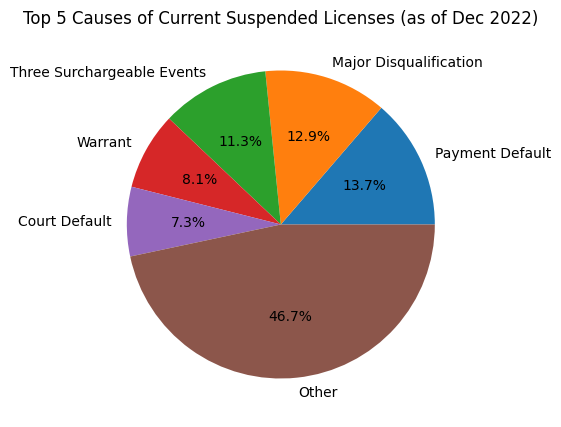

In [11]:
# pyright: reportCallIssue=false

top_num = 5
cur_grouped_sorted = cur_suspended.groupby('Description').size().sort_values(ascending=False)
cur_grouped = cur_grouped_sorted[:top_num]
cur_grouped['Other'] = cur_grouped_sorted[top_num:].sum()

display(cur_grouped)

plt.figure(figsize=(5, 5))
plt.title(f'Top {top_num} Causes of Current Suspended Licenses (as of Dec 2022)')
plt.pie(cur_grouped, labels=[i.title() for i in cur_grouped.index], autopct='%1.1f%%')
plt.savefig(img_path / f'top_{top_num}_suspended_license_causes.png')
plt.show()

In [12]:
del cur_grouped, cur_grouped_sorted

In [13]:
# pyright: reportCallIssue=false

cur_counting = cur_suspended.groupby('Description').size().sort_values(ascending=False).to_frame()

cur_counting.rename(columns={0: 'Amount'}, inplace=True)

cur_counting['Cumulative'] = cur_counting['Amount'].cumsum()

cur_counting['Percentage'] = cur_counting['Amount'] / cur_counting['Amount'].sum()
cur_counting['Cumulative Percentage'] = cur_counting['Percentage'].cumsum()

cur_counting.head(10)

,Amount,Cumulative,Percentage,Cumulative Percentage
Description,,,,
PAYMENT DEFAULT,94842,94842,0.136837,0.136837
Major Disqualification,89586,184428,0.129254,0.266091
Three Surchargeable Events,78437,262865,0.113168,0.379260
WARRANT,56358,319223,0.081313,0.460573
COURT DEFAULT,50451,369674,0.072790,0.533363
Ignition Interlock Device,48076,417750,0.069364,0.602727
NON-PAYMENT OF CHILD SUPPORT,39312,457062,0.056719,0.659446
COMPLAINT MEDICAL,30162,487224,0.043518,0.702963
IMMEDIATE THREAT,22292,509516,0.032163,0.735126


In [14]:
default = cur_suspended.query("Description == 'PAYMENT DEFAULT' & Term == 'Indefinite'")
print(f'{default.shape[0]} suspensions due to payment default, {round(default.shape[0]/cur_suspended.shape[0]*100, 3)}% of {cur_suspended.shape[0]} total suspensions')

del default

94841 suspensions due to payment default, 13.684% of 693100 total suspensions


In [15]:
# pyright: reportArgumentType=false

reasons_path = pathlib.Path.cwd().parent.joinpath('data', 'suspension_reasons_classified.xlsx')

reasons = pd.read_excel(reasons_path, engine='calamine')
reasons.loc[:, 'dangerous'] = reasons['dangerous'].apply(lambda x: bool(x) if x == 0 or x == 1 else x)
reasons

,Description,count,dangerous,debt_based,undefined
0,PAYMENT DEFAULT,180091,False,True,False
1,Three Surchargeable Events,162663,True,False,False
2,Major Disqualification,121275,True,False,False
3,Reciprocal Suspension,62833,NaN,False,True
4,WARRANT,60608,False,False,False
...,...,...,...,...,...
198,RDR __ RESUSP DRUGS,1,False,False,False
199,CHEMICAL TEST REFUSAL,1,False,False,False
200,CHEAT ON CDL EXAM,1,False,False,False
201,B22 - DRIVING WHILE CANCELED,1,False,False,False


In [16]:
cur_reason = cur_suspended.merge(reasons, on='Description', how='left')
cur_reason.head()

,Description,Term,Days Sus/Rev,count,dangerous,debt_based,undefined
0,COURT DEFAULT,Indefinite,INDEFINITE,51047,False,False,False
1,W00 - Non-ACD withdrawal,Indefinite,INDEFINITE,7158,False,False,False
2,Ignition Interlock Device,Indefinite,INDEFINITE,54710,True,False,False
3,W00 - Non-ACD withdrawal,Indefinite,INDEFINITE,7158,False,False,False
4,FSU __ 5 SURCHARGE EVENTS,Indefinite,INDEFINITE,22802,True,False,False


In [17]:
cur_dangerous = cur_reason.groupby('dangerous').size().to_frame()
cur_dangerous.rename(columns={0: 'Amount'}, inplace=True)
cur_dangerous['Percentage'] = cur_dangerous['Amount'] / cur_dangerous['Amount'].sum()

cur_dangerous

,Amount,Percentage
dangerous,,
False,302404,0.448917
True,371226,0.551083


In [18]:
cur_debt = cur_reason.groupby('debt_based').size().to_frame()
cur_debt.rename(columns={0: 'Amount'}, inplace=True)
cur_debt['Percentage'] = cur_debt['Amount'] / cur_debt['Amount'].sum()

cur_debt

,Amount,Percentage
debt_based,,
False,541969,0.781949
True,151131,0.218051


In [19]:
sus_reason = suspension.merge(reasons, on='Description')
sus_reason

,Year,Description,Term,count,dangerous,debt_based,undefined
0,2020,Operating Under Influence (OUI),Definite,48814,True,False,False
1,2020,Operating Under Influence (OUI),Definite,48814,True,False,False
2,2020,Operating Under Influence (OUI),Definite,48814,True,False,False
3,2020,Ignition Interlock Device,Indefinite,54710,True,False,False
4,2020,Operating Under Influence (OUI),Definite,48814,True,False,False
...,...,...,...,...,...,...,...
342778,2022,COMPLAINT REGULATORY,Indefinite,7553,False,False,False
342779,2022,Operating Under Influence (OUI),Definite,48814,True,False,False
342780,2022,Operating Under Influence (OUI),Definite,48814,True,False,False
342781,2022,B26 - Driving while suspended,Definite,4748,False,False,False


In [20]:
dd_by_year = sus_reason.groupby(['Year']).agg({
        'dangerous': 'sum', 
        'Description': 'count',
        'debt_based': 'sum',
    }).rename(columns={
        'dangerous': 'dangerous_count', 
        'Description': 'total_count'
    })
    
dd_by_year['dangerous_ratio'] = dd_by_year['dangerous_count'] / dd_by_year['total_count']
dd_by_year['not_dangerous_count'] = dd_by_year['total_count'] - dd_by_year['dangerous_count']
dd_by_year['not_dangerous_ratio'] = 1 - dd_by_year['dangerous_ratio']

dd_by_year['debt_based_ratio'] = dd_by_year['debt_based'] / dd_by_year['total_count']
dd_by_year['not_debt_based'] = dd_by_year['total_count'] - dd_by_year['debt_based']

dd_by_year = dd_by_year[[
    'dangerous_count', 
    'dangerous_ratio', 
    'not_dangerous_count',
    'not_dangerous_ratio',
    'debt_based', 
    'debt_based_ratio', 
    'not_debt_based', 
    'total_count'
    ]]

dd_by_year

,dangerous_count,dangerous_ratio,not_dangerous_count,not_dangerous_ratio,debt_based,debt_based_ratio,not_debt_based,total_count
Year,,,,,,,,
2020,79563,0.680951,37278,0.319049,21142,0.180947,95699,116841
2021,60557,0.543883,50785,0.456117,20052,0.180094,91290,111342
2022,58713,0.51233,55887,0.48767,23160,0.202094,91440,114600


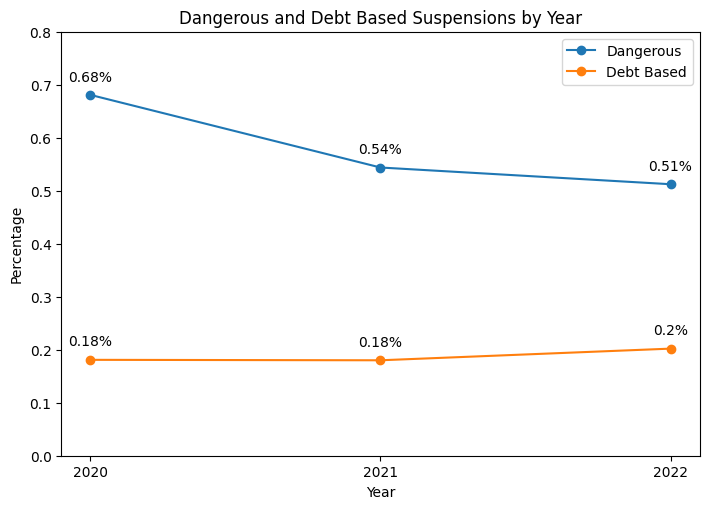

In [21]:
plt.figure(figsize=(7, 5))
plt.title('Dangerous and Debt Based Suspensions by Year')

plt.plot(dd_by_year.index, dd_by_year['dangerous_ratio'], label='Dangerous', marker='o')
plt.plot(dd_by_year.index, dd_by_year['debt_based_ratio'], label='Debt Based', marker='o')

plt.xticks(dd_by_year.index)

for i, v in zip(dd_by_year.index, dd_by_year['dangerous_ratio']):
    plt.annotate(
        f'{round(v, 2)}%',
        (i, v),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center'
    )

for i, v in zip(dd_by_year.index, dd_by_year['debt_based_ratio']):
    plt.annotate(
        f'{round(v, 2)}%',
        (i, v),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center',
    )

plt.tight_layout()
plt.ylim(0, 0.8)

plt.xlabel('Year')
plt.ylabel('Percentage')

del dd_by_year

plt.savefig(img_path / 'dangerous_debt_based_suspensions_by_year.png')
plt.legend()
plt.show()

In [22]:
hypothesis_table = sus_reason.query('dangerous == False & debt_based == True')
hypothesis_table

,Year,Description,Term,count,dangerous,debt_based,undefined
98,2020,PAYMENT DEFAULT,Indefinite,180091,False,True,False
2156,2020,PAYMENT DEFAULT,Indefinite,180091,False,True,False
8166,2020,PAYMENT DEFAULT,Indefinite,180091,False,True,False
8171,2020,PAYMENT DEFAULT,Indefinite,180091,False,True,False
8194,2020,PAYMENT DEFAULT,Indefinite,180091,False,True,False
...,...,...,...,...,...,...,...
342749,2022,PAYMENT DEFAULT,Indefinite,180091,False,True,False
342750,2022,PAYMENT DEFAULT,Indefinite,180091,False,True,False
342752,2022,PAYMENT DEFAULT,Indefinite,180091,False,True,False
342753,2022,PAYMENT DEFAULT,Indefinite,180091,False,True,False


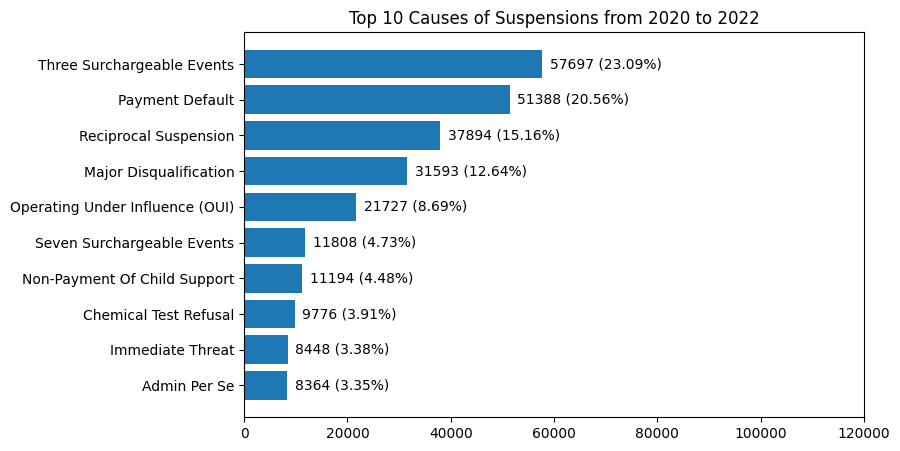

In [23]:
x: int = 10

plt.figure(figsize=(8, 5))
plt.title(f'Top {x} Causes of Suspensions from 2020 to 2022')

temp_df = suspension.copy()
temp_df['Description'] = temp_df['Description'].str.title()
temp_df['Description'] = temp_df['Description'].str.replace('Oui', 'OUI')

temp_df = temp_df.groupby('Description').size().sort_values(ascending=False).to_frame()
non_x = temp_df.iloc[x:].sum()
temp_df = temp_df.iloc[:x]

# temp_df.loc['Other'] = non_x


plt.barh(temp_df.index[::-1], temp_df[0][::-1])

plt.xlim(0, 120000)

for i, v in enumerate(temp_df[0][::-1]):
    plt.text(v+1500, i, f'{str(v)} ({v/temp_df[0].sum()*100:.2f}%)', ha='left', va='center')
    
plt.show()

0 92894
1 249889


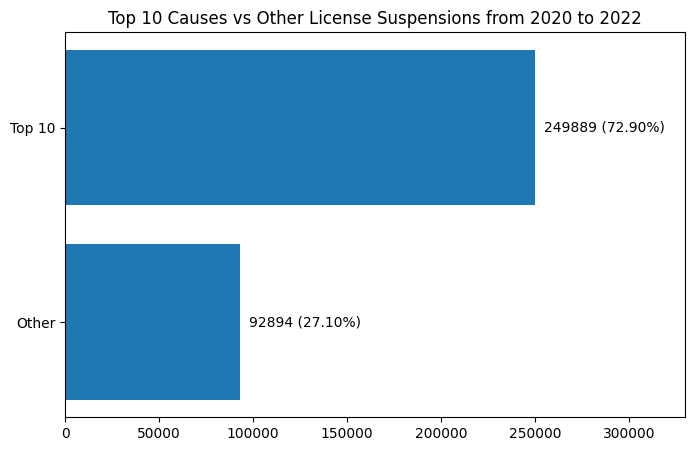

In [24]:
split_df = temp_df.iloc[:x].sum()
split_df.index = ['Top 10']

# non_x = temp_df.iloc[x:].sum()
split_df.loc['Other'] = non_x[0]
split_df = split_df.to_frame()
split_df.sort_values(0, ascending=True, inplace=True)

plt.figure(figsize=(8, 5))
plt.title(f'Top {x} Causes vs Other License Suspensions from 2020 to 2022')
plt.barh(split_df.index, split_df[0])

plt.xlim(0, 330000)

for i, v in enumerate(split_df[0]):
    print(i, v)
    plt.text(v+5000, i, f'{str(v)} ({v/split_df[0].sum()*100:.2f}%)', ha='left', va='center')
    
del split_df, temp_df, non_x
    
plt.show()


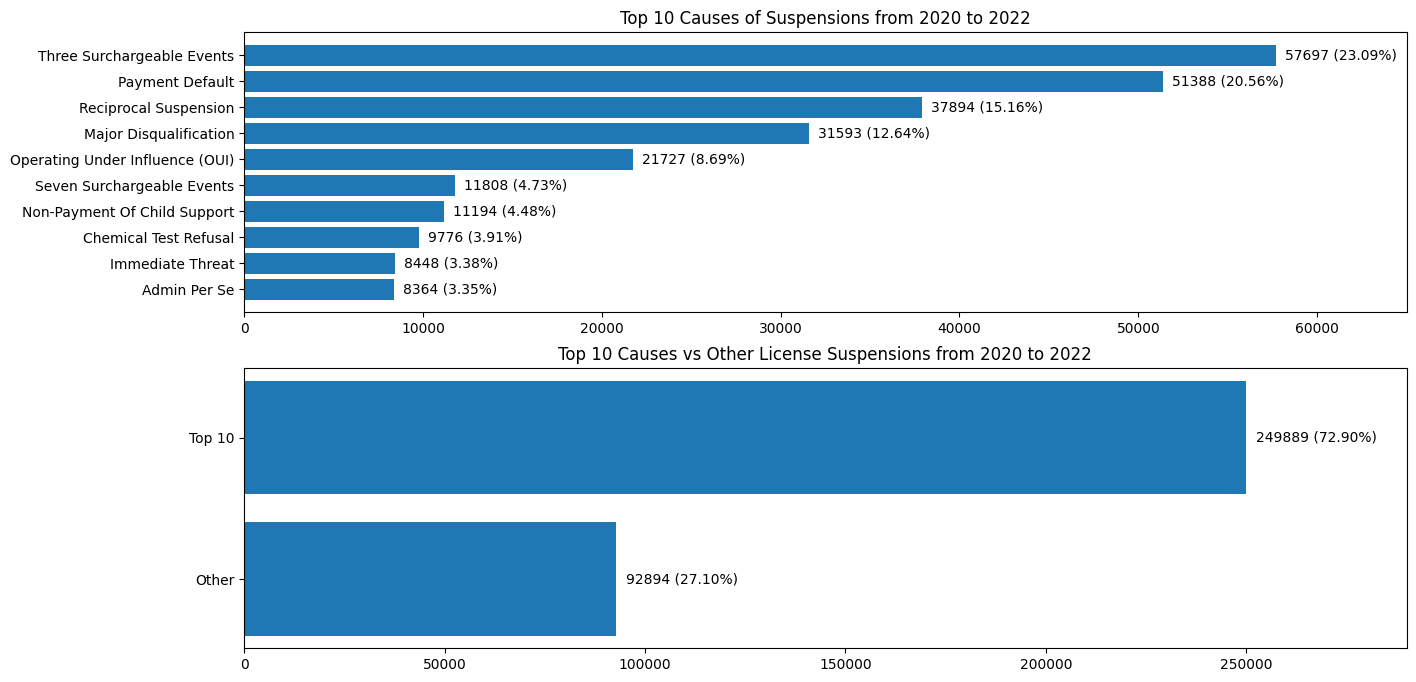

In [25]:
fig, axs = plt.subplots(2, 1, figsize=(15, 8))

x: int = 10

temp_df = suspension.copy()
temp_df['Description'] = temp_df['Description'].str.title()
temp_df['Description'] = temp_df['Description'].str.replace('Oui', 'OUI')

temp_df = temp_df.groupby('Description').size().sort_values(ascending=False).to_frame()
non_x = temp_df.iloc[x:].sum()
temp_df = temp_df.iloc[:x]

# temp_df.loc['Other'] = non_x


axs[0].barh(temp_df.index[::-1], temp_df[0][::-1])
axs[0].title.set_text(f'Top {x} Causes of Suspensions from 2020 to 2022')

axs[0].set_xlim(0, 65000)

for i, v in enumerate(temp_df[0][::-1]):
    axs[0].text(v+500, i, f'{str(v)} ({v/temp_df[0].sum()*100:.2f}%)', ha='left', va='center')
    
    
split_df = temp_df.iloc[:x].sum()
split_df.index = ['Top 10']

# non_x = temp_df.iloc[x:].sum()
split_df.loc['Other'] = non_x[0]
split_df = split_df.to_frame()
split_df.sort_values(0, ascending=True, inplace=True)

# axs[1].figure(figsize=(8, 5))
axs[1].title.set_text(f'Top {x} Causes vs Other License Suspensions from 2020 to 2022')
axs[1].barh(split_df.index, split_df[0])

axs[1].set_xlim(0, 290000)

for i, v in enumerate(split_df[0]):
    axs[1].text(v+2500, i, f'{str(v)} ({v/split_df[0].sum()*100:.2f}%)', ha='left', va='center')

del split_df, temp_df, non_x

plt.show()

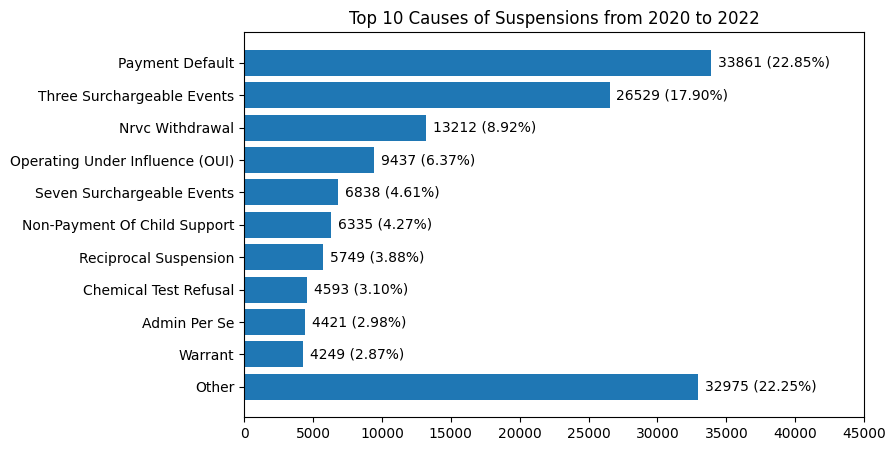

In [26]:
x: int = 10

plt.figure(figsize=(8, 5))
plt.title(f'Top {x} Causes of Suspensions from 2020 to 2022')

temp_df = reinstatement.copy()
temp_df['Sanction Description'] = temp_df['Sanction Description'].str.title()
temp_df['Sanction Description'] = temp_df['Sanction Description'].str.replace('Oui', 'OUI')

temp_df = temp_df.groupby('Sanction Description').size().sort_values(ascending=False).to_frame()
non_x = temp_df.iloc[x:].sum()
temp_df = temp_df.iloc[:x]

temp_df.loc['Other'] = non_x


plt.barh(temp_df.index[::-1], temp_df[0][::-1])

plt.xlim(0, 45000)

for i, v in enumerate(temp_df[0][::-1]):
    plt.text(v+500, i, f'{str(v)} ({v/temp_df[0].sum()*100:.2f}%)', ha='left', va='center')
    
del temp_df, non_x
    
plt.show()

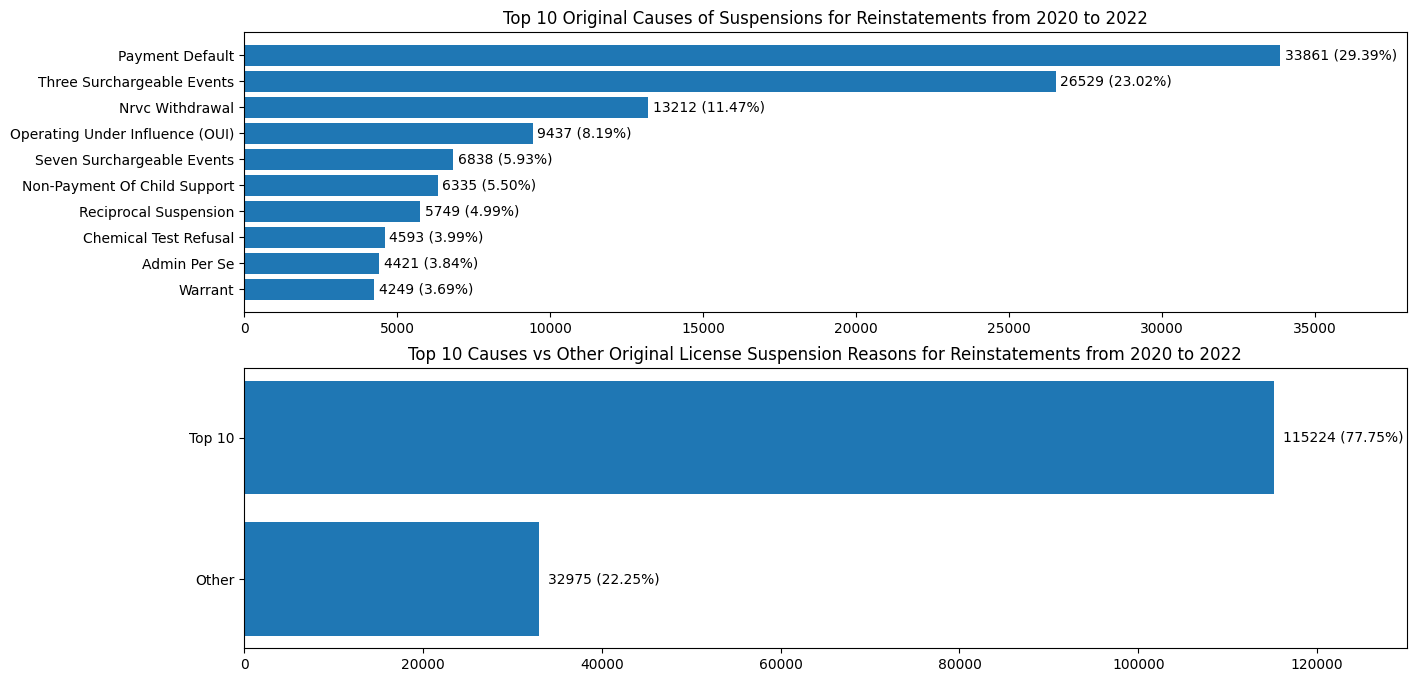

In [27]:
fig, axs = plt.subplots(2, 1, figsize=(15, 8))

x: int = 10

temp_df = reinstatement.copy()
temp_df['Sanction Description'] = temp_df['Sanction Description'].str.title()
temp_df['Sanction Description'] = temp_df['Sanction Description'].str.replace('Oui', 'OUI')

temp_df = temp_df.groupby('Sanction Description').size().sort_values(ascending=False).to_frame()
non_x = temp_df.iloc[x:].sum()
temp_df = temp_df.iloc[:x]

# temp_df.loc['Other'] = non_x


axs[0].barh(temp_df.index[::-1], temp_df[0][::-1])
axs[0].title.set_text(f'Top {x} Original Causes of Suspensions for Reinstatements from 2020 to 2022')

axs[0].set_xlim(0, 38000)

for i, v in enumerate(temp_df[0][::-1]):
    axs[0].text(v+150, i, f'{str(v)} ({v/temp_df[0].sum()*100:.2f}%)', ha='left', va='center')
    
    
split_df = temp_df.iloc[:x].sum()
split_df.index = ['Top 10']

# non_x = temp_df.iloc[x:].sum()
split_df.loc['Other'] = non_x[0]
split_df = split_df.to_frame()
split_df.sort_values(0, ascending=True, inplace=True)

# axs[1].figure(figsize=(8, 5))
axs[1].title.set_text(f'Top {x} Causes vs Other Original License Suspension Reasons for Reinstatements from 2020 to 2022')
axs[1].barh(split_df.index, split_df[0])

axs[1].set_xlim(0, 130000)

for i, v in enumerate(split_df[0]):
    axs[1].text(v+1000, i, f'{str(v)} ({v/split_df[0].sum()*100:.2f}%)', ha='left', va='center')

del split_df, temp_df, non_x

plt.show()

In [28]:
cur_suspended

,Description,Term,Days Sus/Rev
0,COURT DEFAULT,Indefinite,INDEFINITE
1,W00 - Non-ACD withdrawal,Indefinite,INDEFINITE
2,Ignition Interlock Device,Indefinite,INDEFINITE
3,W00 - Non-ACD withdrawal,Indefinite,INDEFINITE
4,FSU __ 5 SURCHARGE EVENTS,Indefinite,INDEFINITE
...,...,...,...
693095,Massachusetts Disqualification,Lifetime,INDEFINITE
693096,Chemical Test Refusal,Definite,1095
693097,Chemical Test Refusal,Definite,180
693098,Massachusetts Disqualification,Definite,365


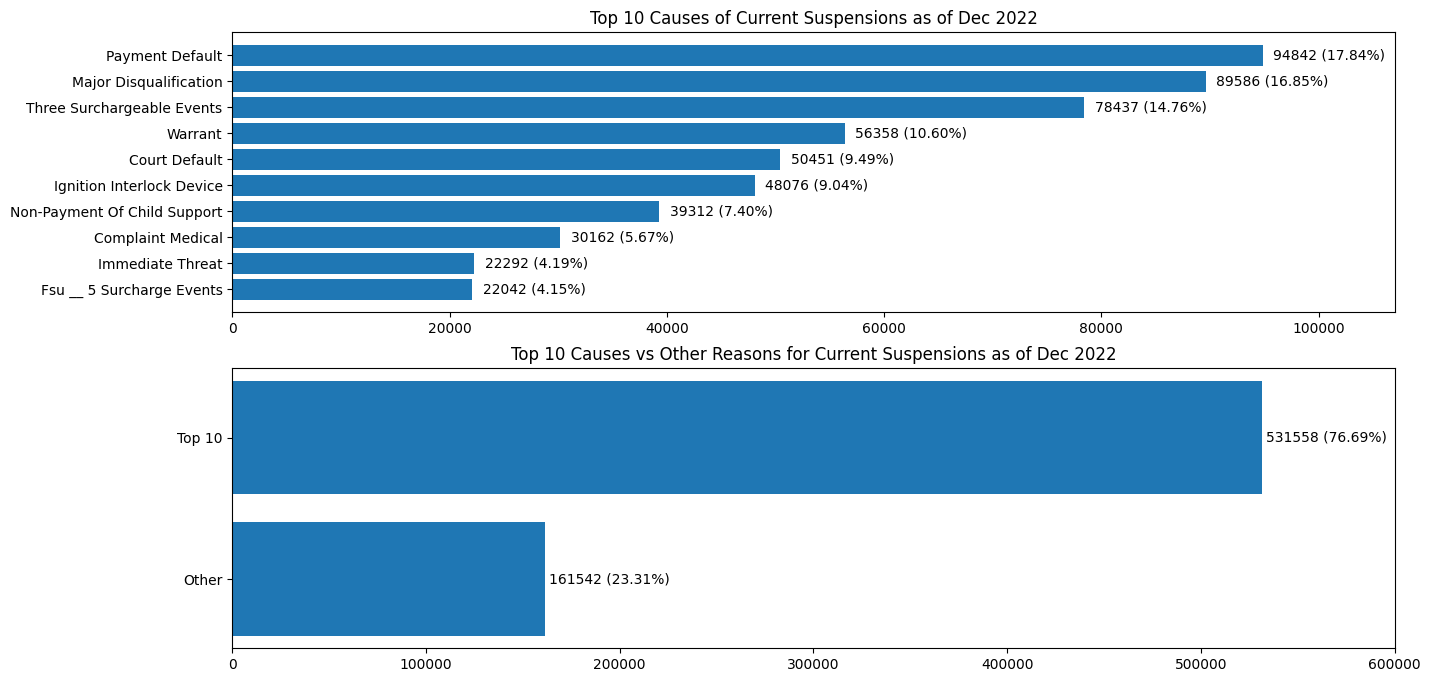

In [29]:
# pyright: reportCallIssue=false, reportAttributeAccessIssue=false, reportArgumentType=false
fig, axs = plt.subplots(2, 1, figsize=(15, 8))

x: int = 10

temp_df = cur_suspended.copy()
temp_df['Description'] = temp_df['Description'].str.title()
temp_df['Description'] = temp_df['Description'].str.replace('Oui', 'OUI')

temp_df = temp_df.groupby('Description').size().sort_values(ascending=False).to_frame()
non_x = temp_df.iloc[x:].sum()
temp_df = temp_df.iloc[:x]

# temp_df.loc['Other'] = non_x


axs[0].barh(temp_df.index[::-1], temp_df[0][::-1])
axs[0].title.set_text(f'Top {x} Causes of Current Suspensions as of Dec 2022')

axs[0].set_xlim(0, 107000)

for i, v in enumerate(temp_df[0][::-1]):
    axs[0].text(v+1000, i, f'{str(v)} ({v/temp_df[0].sum()*100:.2f}%)', ha='left', va='center')
    
    
split_df = temp_df.iloc[:x].sum()
split_df.index = ['Top 10']

# non_x = temp_df.iloc[x:].sum()
split_df.loc['Other'] = non_x[0]
split_df = split_df.to_frame()
split_df.sort_values(0, ascending=True, inplace=True)

# axs[1].figure(figsize=(8, 5))
axs[1].title.set_text(f'Top {x} Causes vs Other Reasons for Current Suspensions as of Dec 2022')
axs[1].barh(split_df.index, split_df[0])

axs[1].set_xlim(0, 600000)

for i, v in enumerate(split_df[0]):
    axs[1].text(v+2000, i, f'{str(v)} ({v/split_df[0].sum()*100:.2f}%)', ha='left', va='center')

del split_df, temp_df, non_x

plt.show()

In [30]:
gc.collect()

25869

# Rachel's Work

Minor tweaks have been made to make her code work with mine.

---

## Classified Data

In [31]:
classified = pd.read_excel(reasons_path, engine='calamine')
classified.loc[:, 'dangerous'] = classified['dangerous'].apply(lambda x: bool(x) if x == 0 or x == 1 else 'Uncoded')

classified

,Description,count,dangerous,debt_based,undefined
0,PAYMENT DEFAULT,180091,False,True,False
1,Three Surchargeable Events,162663,True,False,False
2,Major Disqualification,121275,True,False,False
3,Reciprocal Suspension,62833,Uncoded,False,True
4,WARRANT,60608,False,False,False
...,...,...,...,...,...
198,RDR __ RESUSP DRUGS,1,False,False,False
199,CHEMICAL TEST REFUSAL,1,False,False,False
200,CHEAT ON CDL EXAM,1,False,False,False
201,B22 - DRIVING WHILE CANCELED,1,False,False,False


## Tableau/Visualization Dataset

In [32]:
# pyright: reportCallIssue=false, reportArgumentType=false

#import reinstated data

#Choose the columns to be analyzed
col_ri = ['Year Reinstated','Sanction Description', 'Term', 'Days Sus/Rev']

#Read the CSV files 
ri_2020 = pd.read_excel(reinstatement_path, usecols=col_ri, dtype=str, sheet_name=0, engine='calamine')
ri_2021 = pd.read_excel(reinstatement_path, usecols=col_ri, dtype=str, sheet_name=1, engine='calamine')
ri_2022 = pd.read_excel(reinstatement_path, usecols=col_ri, dtype=str, sheet_name=2, engine='calamine')

#Combine the csv files
ri = pd.concat([ri_2020, ri_2021, ri_2022], axis=0)

ri.rename(columns = {"Sanction Description": "Description"}, inplace=True)

#Insert a column that labels the data points as the dataset they're from
ri = ri.assign(Dataset = 'Reinstated')
cols = ri.columns.tolist()
cols = cols[-1:] + cols[:-1]
ri = ri[cols]

ri= ri.rename(columns = {"Days Sus/Rev": "Days_suspended", "Year Reinstated": "Year"})
ri

,Dataset,Year,Description,Term,Days_suspended
0,Reinstated,2020,NON-PAYMENT OF CHILD SUPPORT,Indefinite,1072
1,Reinstated,2020,PROPERTY DAMAGE CLAIM,Indefinite,714
2,Reinstated,2020,NRVC Withdrawal,Indefinite,1191
3,Reinstated,2020,NRVC Withdrawal,Indefinite,924
4,Reinstated,2020,94C35 __ PRESENT WITH HEROIN,Definite,365
...,...,...,...,...,...
27887,Reinstated,2022,Three Surchargeable Events,Indefinite,1431
27888,Reinstated,2022,UNINSURED MOTOR VEHICLE c90 §34J,Definite,60
27889,Reinstated,2022,PAYMENT DEFAULT,Indefinite,66
27890,Reinstated,2022,COMPLAINT FRAUDULENT LICENSE/ID,Indefinite,180


In [33]:
# pyright: reportCallIssue=false, reportArgumentType=false

# Read the csv's 

#Choose the columns to be analyzed
col_si = ['Year','Description', 'Term', 'Days Sus/Rev']

#Read the CSV files 
si_2020 = pd.read_excel(suspension_path, usecols=col_si, dtype=str, sheet_name=0, engine='calamine')
si_2021 = pd.read_excel(suspension_path, usecols=col_si, dtype=str, sheet_name=1, engine='calamine')
si_2022 = pd.read_excel(suspension_path, usecols=col_si, dtype=str, sheet_name=2, engine='calamine')

#Combine the csv files
si = pd.concat([si_2020, si_2021, si_2022], axis=0)

#Insert a column that labels the data points as the dataset they're from
si = si.assign(Dataset = 'Suspensions Initiated')
col_si = si.columns.tolist()
col_si = col_si[-1:] + col_si[:-1]
si = si[col_si]

si = si.rename(columns = {"Days Sus/Rev": "Days_suspended"})
si

,Dataset,Year,Description,Term,Days_suspended
0,Suspensions Initiated,2020,Operating Under Influence (OUI),Definite,2920
1,Suspensions Initiated,2020,Operating Under Influence (OUI),Definite,730
2,Suspensions Initiated,2020,Operating Under Influence (OUI),Definite,2920
3,Suspensions Initiated,2020,Ignition Interlock Device,Indefinite,INDEFINITE
4,Suspensions Initiated,2020,Operating Under Influence (OUI),Definite,730
...,...,...,...,...,...
114595,Suspensions Initiated,2022,COMPLAINT REGULATORY,Indefinite,10
114596,Suspensions Initiated,2022,Operating Under Influence (OUI),Definite,45
114597,Suspensions Initiated,2022,Operating Under Influence (OUI),Definite,45
114598,Suspensions Initiated,2022,B26 - Driving while suspended,Definite,60


In [34]:
# pyright: reportCallIssue=false, reportArgumentType=false

col_current = ['Description', 'Term', 'Days Sus/Rev']

current = pd.read_excel(cur_suspended_path, usecols=col_current, dtype=str, sheet_name=0, engine='calamine')

#Insert a column that labels the data points as the dataset they're from
current = current.assign(Dataset = 'Currently suspended')
current = current.assign(Year = 2022)
col_current = current.columns.tolist()
col_current = col_current[-2:] + col_current[:-2]
current = current[col_current]

current = current.rename(columns = {"Days Sus/Rev": "Days_suspended"})
current

,Dataset,Year,Description,Term,Days_suspended
0,Currently suspended,2022,COURT DEFAULT,Indefinite,INDEFINITE
1,Currently suspended,2022,W00 - Non-ACD withdrawal,Indefinite,INDEFINITE
2,Currently suspended,2022,Ignition Interlock Device,Indefinite,INDEFINITE
3,Currently suspended,2022,W00 - Non-ACD withdrawal,Indefinite,INDEFINITE
4,Currently suspended,2022,FSU __ 5 SURCHARGE EVENTS,Indefinite,INDEFINITE
...,...,...,...,...,...
693095,Currently suspended,2022,Massachusetts Disqualification,Lifetime,INDEFINITE
693096,Currently suspended,2022,Chemical Test Refusal,Definite,1095
693097,Currently suspended,2022,Chemical Test Refusal,Definite,180
693098,Currently suspended,2022,Massachusetts Disqualification,Definite,365


In [35]:
tableau_data = pd.concat([ri, si, current], axis=0)
tableau_data

,Dataset,Year,Description,Term,Days_suspended
0,Reinstated,2020,NON-PAYMENT OF CHILD SUPPORT,Indefinite,1072
1,Reinstated,2020,PROPERTY DAMAGE CLAIM,Indefinite,714
2,Reinstated,2020,NRVC Withdrawal,Indefinite,1191
3,Reinstated,2020,NRVC Withdrawal,Indefinite,924
4,Reinstated,2020,94C35 __ PRESENT WITH HEROIN,Definite,365
...,...,...,...,...,...
693095,Currently suspended,2022,Massachusetts Disqualification,Lifetime,INDEFINITE
693096,Currently suspended,2022,Chemical Test Refusal,Definite,1095
693097,Currently suspended,2022,Chemical Test Refusal,Definite,180
693098,Currently suspended,2022,Massachusetts Disqualification,Definite,365


In [36]:
tableau_data2 = pd.merge(tableau_data, classified, on='Description', how='left')
tableau_data2.drop("count", axis = 1)

,Dataset,Year,Description,Term,Days_suspended,dangerous,debt_based,undefined
0,Reinstated,2020,NON-PAYMENT OF CHILD SUPPORT,Indefinite,1072,False,True,False
1,Reinstated,2020,PROPERTY DAMAGE CLAIM,Indefinite,714,False,False,False
2,Reinstated,2020,NRVC Withdrawal,Indefinite,1191,True,False,False
3,Reinstated,2020,NRVC Withdrawal,Indefinite,924,True,False,False
4,Reinstated,2020,94C35 __ PRESENT WITH HEROIN,Definite,365,False,False,False
...,...,...,...,...,...,...,...,...
1184077,Currently suspended,2022,Massachusetts Disqualification,Lifetime,INDEFINITE,True,False,False
1184078,Currently suspended,2022,Chemical Test Refusal,Definite,1095,False,False,False
1184079,Currently suspended,2022,Chemical Test Refusal,Definite,180,False,False,False
1184080,Currently suspended,2022,Massachusetts Disqualification,Definite,365,True,False,False


In [37]:
# Force conversion to str as df.astype("object") doesn't work
tableau_data2["dangerous"] = tableau_data2["dangerous"].apply(lambda x: str(x))
tableau_data2['Year'] = tableau_data2['Year'].apply(lambda x: str(x))

Data is being stored as parquet due to GitHub file size limits, however a csv will still be created locally for Tableau.

In [38]:
from pathlib import Path  
filepath = Path().cwd().parent / "data"
filepath.parent.mkdir(parents=True, exist_ok=True)  
tableau_data2.to_csv(filepath / "tableau_data.csv")
tableau_data2.to_parquet(filepath / "tableau_data.parquet")

In [39]:
tableau_data2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1184082 entries, 0 to 1184081
Data columns (total 9 columns):
 #   Column          Non-Null Count    Dtype 
---  ------          --------------    ----- 
 0   Dataset         1184082 non-null  object
 1   Year            1184082 non-null  object
 2   Description     1184082 non-null  object
 3   Term            1166463 non-null  object
 4   Days_suspended  1184082 non-null  object
 5   count           1184082 non-null  int64 
 6   dangerous       1184082 non-null  object
 7   debt_based      1184082 non-null  bool  
 8   undefined       1184082 non-null  bool  
dtypes: bool(2), int64(1), object(6)
memory usage: 65.5+ MB


## 1. What are the reasons for license suspensions?

In [40]:
display(ri['Description'].nunique())
display(si['Description'].nunique())
display(current['Description'].nunique())

156

157

162

# Debt-Based by Year

## Suspensions Initiated

In [41]:
#merge with classifications 
graph_si = pd.merge(si, classified, on='Description', how='left')

cols_si= ["Dataset", "Days_suspended", "count", "undefined"]
graph_si = graph_si.drop(cols_si, axis =1)
graph_si.head()

,Year,Description,Term,dangerous,debt_based
0,2020,Operating Under Influence (OUI),Definite,True,False
1,2020,Operating Under Influence (OUI),Definite,True,False
2,2020,Operating Under Influence (OUI),Definite,True,False
3,2020,Ignition Interlock Device,Indefinite,True,False
4,2020,Operating Under Influence (OUI),Definite,True,False


In [42]:
graph_si.isnull().sum().to_frame().T

,Year,Description,Term,dangerous,debt_based
0,0,0,6680,0,0


In [43]:
year_groups = graph_si.groupby('Year')['debt_based'].agg(['count', 'sum']).reset_index()
year_groups["percent"] = round((year_groups["sum"]/year_groups["count"])*100, 2)
year_groups

,Year,count,sum,percent
0,2020,116841,21142,18.09
1,2021,111342,20052,18.01
2,2022,114600,23160,20.21


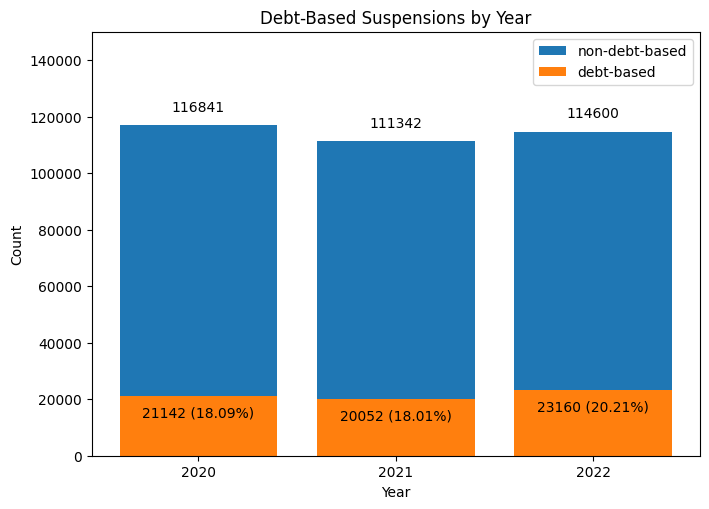

In [44]:
plt.figure(figsize=(7, 5))
plt.title('Debt-Based Suspensions by Year')

plt.bar(year_groups['Year'], year_groups['count'], label='non-debt-based')
plt.bar(year_groups['Year'], year_groups['sum'], label='debt-based')

plt.xticks(year_groups['Year'])

for i, v in zip(year_groups['Year'], year_groups['count']):
    plt.annotate(
        f'{round(v, 2)}',
        (i, v),
        textcoords="offset points",
        xytext=(0, 10),
        ha='center'
    )

for i, v, p in zip(year_groups['Year'], year_groups['sum'], year_groups['percent']):
    plt.annotate(
        f'{round(v, 2)} ({round(p, 2)}%)',
        (i, v),
        textcoords="offset points",
        xytext=(0, -15),
        ha='center'
    )
plt.ylim(0, 150000)
plt.tight_layout()

plt.xlabel('Year')
plt.ylabel('Count')

#plt.savefig(img_path / 'safe_debtbased_suspensions.png')
plt.legend()
plt.show()

In [45]:
# pyright: reportCallIssue=false, reportArgumentType=false

si_road = graph_si.groupby(['Year', 'dangerous']).size().unstack(fill_value=0)
si_road["total"] = si_road.sum(axis=1)
si_road = si_road.reset_index()
si_road.rename(columns={False: 'False', True: 'True'}, inplace=True)
si_road

dangerous,Year,False,True,Uncoded,total
0,2020,31509,79563,5769,116841
1,2021,30416,60557,20369,111342
2,2022,35767,58713,20120,114600


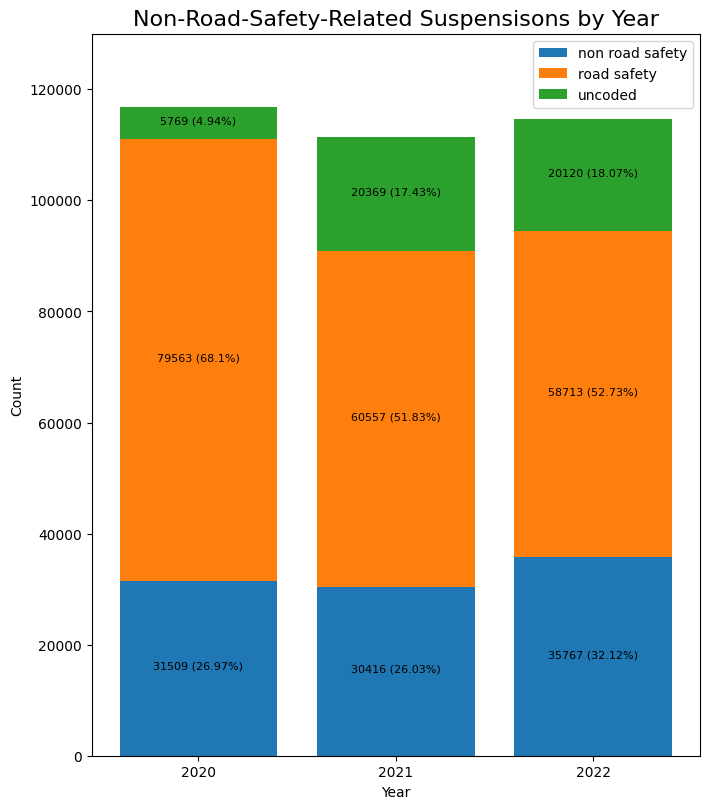

In [46]:
plt.figure(figsize=(7, 8))
plt.title('Non-Road-Safety-Related Suspensisons by Year', fontsize=16)


#plt.bar(si_road['Year'], si_road['total'])
bars1 = plt.bar(si_road['Year'], si_road['False'], label='non road safety')
bars2 = plt.bar(si_road['Year'], si_road['True'], bottom = si_road['False'], label='road safety')
bars3 = plt.bar(si_road['Year'], si_road['Uncoded'], bottom= si_road['False'] + si_road['True'], label='uncoded')

total_year = si_road["total"]
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        year_index = bar.get_x()
        year = si_road['Year'].iloc[int(year_index)]
        total = total_year.iloc[int(year_index)]
        percentage = round((height / total) * 100, 2)
        plt.annotate(f'{height:.0f} ({percentage}%)',
                     xy=(bar.get_x() + bar.get_width() / 2, bar.get_height() / 2+ bar.get_y()),  # Center of each bar
                     xytext=(0, 5),  # Offset for the xytext
                     textcoords="offset points",
                     ha='center', va='top',
                     fontsize=8)  

plt.ylim(0, 130000)
plt.tight_layout()

plt.xlabel('Year')
plt.ylabel('Count')

#plt.savefig(img_path / 'safe_debtbased_suspensions.png')
plt.legend()
plt.show()